# 04 - Comparison of the three models
Run notebooks 01-03 first. This one reads their results and compares the models.

## 1. Imports

In [8]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

## 2. Load the results

In [9]:
results = {name: json.loads((ROOT / "artifacts" / f"{name.lower()}_results.json").read_text()) for name in ["SVM", "MLP", "CNN"]}

## 3. Comparison table
The gap (train accuracy minus test accuracy) shows overfitting: a smaller gap means better generalisation. The table is also saved for the web app.

In [10]:
table = pd.DataFrame(results).T[["test_acc", "train_acc", "train_time", "parameters"]].astype(float)
table.columns = ["test acc", "train acc", "train time (s)", "parameters"]
table["gap (train - test)"] = table["train acc"] - table["test acc"]
table.to_csv(ROOT / "app" / "charts" / "model_comparison.csv")
table

,test acc,train acc,train time (s),parameters,gap (train - test)
SVM,0.9851,0.9999,95.027480,9763152.0,0.0148
MLP,0.9836,0.9977,9.520880,535818.0,0.0141
CNN,0.9902,0.9955,84.631314,220234.0,0.0053


## 4. Chart
Accuracy, training time and size side by side. The chart is also saved for the web app.

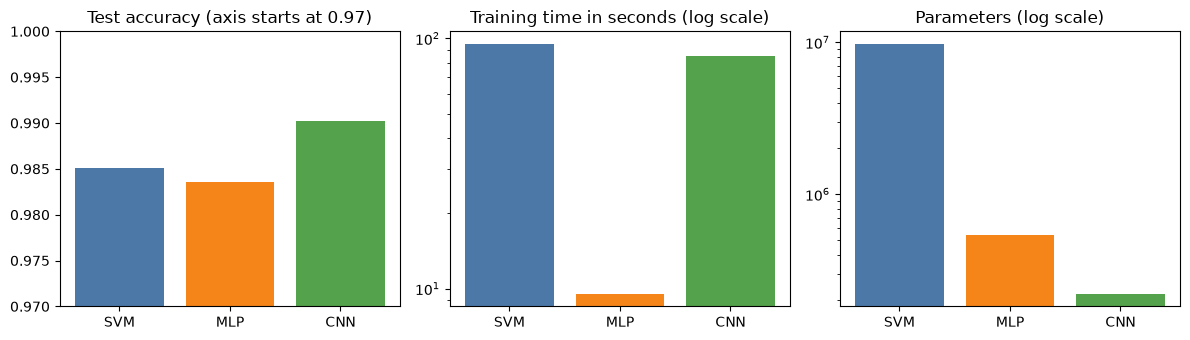

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, title in zip(axes, ["test acc", "train time (s)", "parameters"],
                          ["Test accuracy (axis starts at 0.97)", "Training time in seconds (log scale)", "Parameters (log scale)"]):
    ax.bar(table.index, table[col], color=["#4c78a8", "#f58518", "#54a24b"])
    ax.set_title(title)
    if col != "test acc":
        ax.set_yscale("log")
axes[0].set_ylim(0.97, 1.0)
plt.tight_layout()
plt.savefig(ROOT / "app" / "charts" / "comparison.png", dpi=120)
plt.show()

## 5. Which model wins on each point?

In [12]:
pd.Series({
    "most accurate": table["test acc"].idxmax(),
    "generalises best (smallest gap)": table["gap (train - test)"].idxmin(),
    "fastest to train": table["train time (s)"].idxmin(),
    "simplest (fewest parameters)": table["parameters"].idxmin(),
})

most accurate                      CNN
generalises best (smallest gap)    CNN
fastest to train                   MLP
simplest (fewest parameters)       CNN
dtype: str

## 6. Conclusion
The **CNN** is the best choice for digit recognition: the highest test accuracy, the smallest gap between train and test accuracy (it overfits least) and the fewest parameters. The MLP trains fastest but is the least accurate. The SVM is the slowest to train and by far the largest model.